# 02a — CNN From Scratch: LOCAL CPU SMOKE TEST — NOT FINAL RESULT

## Waste Classification AI — Phase 3 (pipeline verification only)

> ⚠️ **This notebook trains for only a few epochs on a CPU-only laptop, purely to verify that
> the full pipeline (data → augmentation → model → class-weighted loss → training loop →
> checkpointing → evaluation → metrics/figures) runs correctly end-to-end.**
>
> **Every metric produced here is a smoke-test result, not a final result.** The real,
> full-budget training run happens in
> [`02b_cnn_from_scratch_final.ipynb`](02b_cnn_from_scratch_final.ipynb) on a local CUDA GPU.
> All artifacts from this notebook are saved with a `smoke_test` suffix
> (`models/cnn_from_scratch_smoke_test.pt`, `reports/results/cnn_smoke_test_metrics.json`,
> etc.) specifically so they can never be confused with — or accidentally overwrite — the
> final Colab results, which use the plain (`cnn_from_scratch_best.pt`,
> `cnn_test_metrics.json`, ...) filenames.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import json

import torch
import torch.nn as nn

from src.data.dataset import WasteDataset
from src.data.download import download_trashnet
from src.data.splitter import create_stratified_split, load_split_manifest, save_split_manifest
from src.data.transforms import get_eval_transforms, get_train_transforms
from src.evaluation.metrics import (
    get_classification_report,
    get_classification_report_dict,
    get_predictions,
    plot_confusion_matrix,
    plot_training_curves,
)
from src.models.cnn import WasteCNN, count_parameters
from src.training.class_weights import compute_class_weights
from src.training.trainer import fit, save_history
from src.utils.config import BATCH_SIZE, CLASS_NAMES, FIGURES_DIR, MODELS_DIR, RANDOM_SEED, RESULTS_DIR, SPLITS_MANIFEST_PATH
from src.utils.device import get_device
from src.utils.seed import set_seed

set_seed(RANDOM_SEED)
device = get_device()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {device}")
print(f"CUDA available: {torch.cuda.is_available()}")

download_trashnet()
if not SPLITS_MANIFEST_PATH.exists():
    manifest = create_stratified_split()
    save_split_manifest(manifest)
manifest = load_split_manifest()
print(f"Split manifest: {len(manifest)} images")

# Smoke-test-specific output paths (deliberately NOT the canonical Phase 3 filenames)
SMOKE_TEST_CHECKPOINT_PATH = MODELS_DIR / "cnn_from_scratch_smoke_test.pt"
SMOKE_TEST_HISTORY_PATH = RESULTS_DIR / "cnn_smoke_test_history.json"
SMOKE_TEST_METRICS_PATH = RESULTS_DIR / "cnn_smoke_test_metrics.json"
SMOKE_TEST_CURVES_FIG = FIGURES_DIR / "cnn_smoke_test_training_curves.png"
SMOKE_TEST_CM_FIG = FIGURES_DIR / "cnn_smoke_test_confusion_matrix.png"


Device: cpu
CUDA available: False
Dataset already present at C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project\data\raw\dataset-resized, skipping download.
Split manifest: 2527 images


## Data, Model, and Training Setup

Identical to the Colab notebook: same `WasteDataset` + transforms (Phase 2), same
`WasteCNN` architecture (Phase 3), same seed (42), same class-weighted `CrossEntropyLoss`,
same `Adam` optimizer. **The only difference is the epoch budget** — 5 epochs here vs. a
full budget (30, with early stopping) locally on a CUDA GPU GPU.


In [2]:
train_ds = WasteDataset(split="train", transform=get_train_transforms(), manifest=manifest)
val_ds = WasteDataset(split="val", transform=get_eval_transforms(), manifest=manifest)
test_ds = WasteDataset(split="test", transform=get_eval_transforms(), manifest=manifest)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

model = WasteCNN(num_classes=len(CLASS_NAMES), dropout=0.5)
print(count_parameters(model))

SMOKE_TEST_EPOCHS = 5
PATIENCE = 5
LEARNING_RATE = 1e-3

class_weights = compute_class_weights(manifest, split="train").to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(f"SMOKE_TEST_EPOCHS={SMOKE_TEST_EPOCHS}  PATIENCE={PATIENCE}  LEARNING_RATE={LEARNING_RATE}  BATCH_SIZE={BATCH_SIZE}")


Train: 1768 | Val: 379 | Test: 380
{'total_params': 390918, 'trainable_params': 390918, 'frozen_params': 0}
SMOKE_TEST_EPOCHS=5  PATIENCE=5  LEARNING_RATE=0.001  BATCH_SIZE=32


## Training (smoke test — 5 epochs)

In [3]:
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=SMOKE_TEST_EPOCHS,
    checkpoint_path=SMOKE_TEST_CHECKPOINT_PATH,
    patience=PATIENCE,
)

save_history(history, SMOKE_TEST_HISTORY_PATH)
print(f"\n[SMOKE TEST] checkpoint saved to {SMOKE_TEST_CHECKPOINT_PATH}")


Epoch   1/5 | train_loss=1.5092 train_acc=0.3795 | val_loss=1.3574 val_acc=0.3852 | 160.9s  [best, checkpoint saved]


Epoch   2/5 | train_loss=1.3663 train_acc=0.4446 | val_loss=1.4863 val_acc=0.4301 | 155.0s


Epoch   3/5 | train_loss=1.3147 train_acc=0.4791 | val_loss=1.1786 val_acc=0.4934 | 138.0s  [best, checkpoint saved]


Epoch   4/5 | train_loss=1.2848 train_acc=0.4887 | val_loss=1.3284 val_acc=0.5198 | 140.5s


Epoch   5/5 | train_loss=1.2200 train_acc=0.5158 | val_loss=1.2759 val_acc=0.4459 | 141.4s

[SMOKE TEST] checkpoint saved to C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project\models\cnn_from_scratch_smoke_test.pt


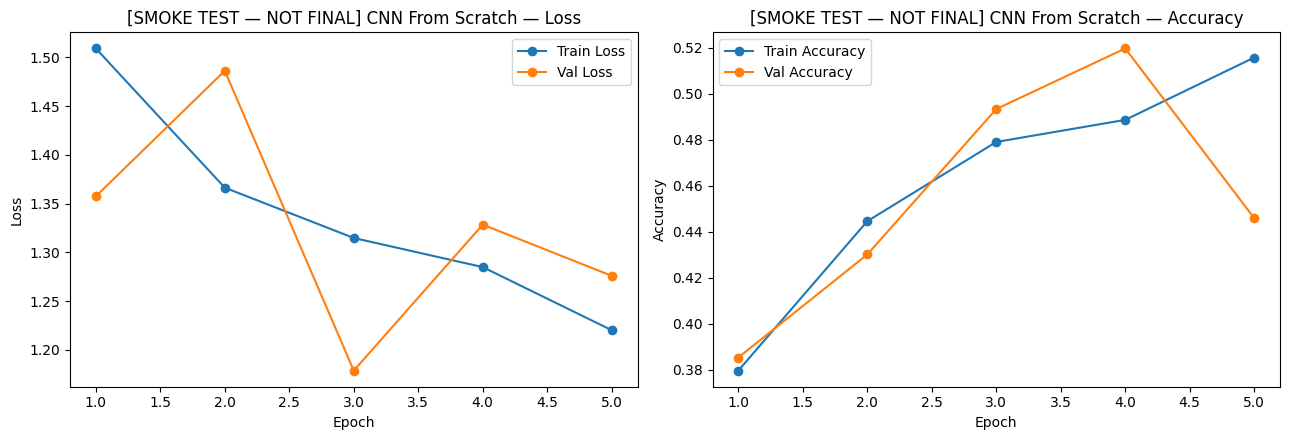

In [4]:
fig = plot_training_curves(
    history,
    title_prefix="[SMOKE TEST — NOT FINAL] CNN From Scratch — ",
    save_path=SMOKE_TEST_CURVES_FIG,
)


**Reading the curves (smoke-test run, 5 epochs, CPU):** Train loss falls steadily and
train accuracy rises steadily epoch over epoch — the model is clearly learning. Validation
loss/accuracy are noisy rather than smoothly improving, which is expected with only 5
epochs on a small dataset — there isn't enough training yet to distinguish "real"
validation improvement from epoch-to-epoch noise, and this looks like early-stage
underfitting (both losses still trending down), not overfitting. The full Colab run (30
epochs with early stopping) should show smoother convergence and will reveal whether
overfitting appears once the model has trained long enough to start memorizing
training-set specifics.


## Test Set Evaluation (smoke test — NOT final)

In [5]:
model.load_state_dict(torch.load(SMOKE_TEST_CHECKPOINT_PATH, map_location=device))
model.to(device)

y_true, y_pred, y_probs = get_predictions(model, test_loader, device)
test_accuracy = (y_true == y_pred).mean()

print("[SMOKE TEST — NOT FINAL RESULT]")
print(f"Test accuracy: {test_accuracy:.4f}\n")
print(get_classification_report(y_true, y_pred, CLASS_NAMES))


[SMOKE TEST — NOT FINAL RESULT]
Test accuracy: 0.4763

              precision    recall  f1-score   support

   cardboard      0.821     0.767     0.793        60
       glass      0.434     0.303     0.357        76
       metal      0.414     0.194     0.264        62
       paper      0.700     0.393     0.504        89
     plastic      0.382     0.644     0.480        73
       trash      0.261     0.900     0.404        20

    accuracy                          0.476       380
   macro avg      0.502     0.533     0.467       380
weighted avg      0.535     0.476     0.471       380



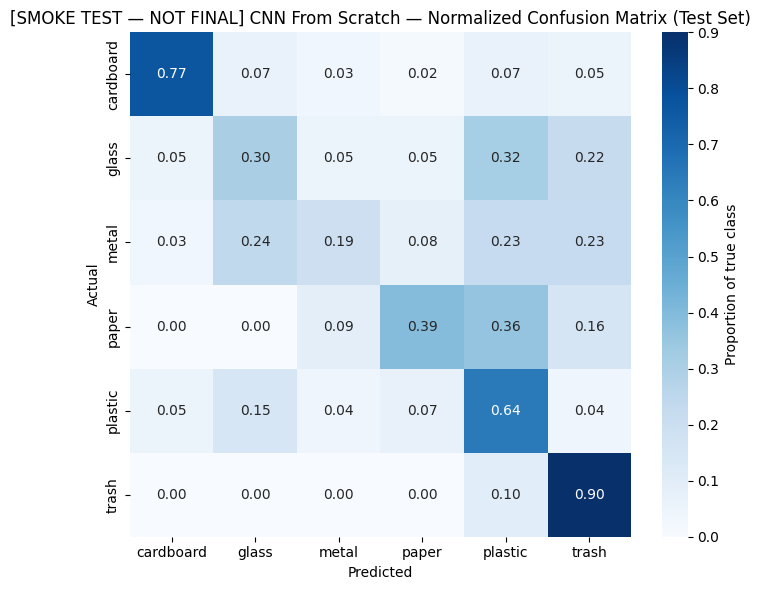

In [6]:
fig = plot_confusion_matrix(
    y_true, y_pred, CLASS_NAMES, normalize=True,
    title="[SMOKE TEST — NOT FINAL] CNN From Scratch — Normalized Confusion Matrix (Test Set)",
    save_path=SMOKE_TEST_CM_FIG,
)


In [7]:
report_dict = get_classification_report_dict(y_true, y_pred, CLASS_NAMES)

results = {
    "LABEL": "LOCAL CPU SMOKE TEST - NOT FINAL RESULT",
    "model_name": "CNN_from_scratch",
    "epochs_run": len(history["train_loss"]),
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": report_dict["macro avg"]["precision"],
    "test_recall_macro": report_dict["macro avg"]["recall"],
    "test_f1_macro": report_dict["macro avg"]["f1-score"],
    "test_precision_weighted": report_dict["weighted avg"]["precision"],
    "test_recall_weighted": report_dict["weighted avg"]["recall"],
    "test_f1_weighted": report_dict["weighted avg"]["f1-score"],
    "per_class": {name: report_dict[name] for name in CLASS_NAMES},
    "total_params": count_parameters(model)["total_params"],
    "trainable_params": count_parameters(model)["trainable_params"],
    "avg_epoch_time_sec": sum(history["epoch_time_sec"]) / len(history["epoch_time_sec"]),
    "total_training_time_sec": sum(history["epoch_time_sec"]),
}

with open(SMOKE_TEST_METRICS_PATH, "w") as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))


{
  "LABEL": "LOCAL CPU SMOKE TEST - NOT FINAL RESULT",
  "model_name": "CNN_from_scratch",
  "epochs_run": 5,
  "test_accuracy": 0.4763157894736842,
  "test_precision_macro": 0.5020278875638988,
  "test_recall_macro": 0.533323446019243,
  "test_f1_macro": 0.46685203339304526,
  "test_precision_weighted": 0.5350887342695166,
  "test_recall_weighted": 0.4763157894736842,
  "test_f1_weighted": 0.4709443843394019,
  "per_class": {
    "cardboard": {
      "precision": 0.8214285714285714,
      "recall": 0.7666666666666667,
      "f1-score": 0.7931034482758621,
      "support": 60.0
    },
    "glass": {
      "precision": 0.4339622641509434,
      "recall": 0.3026315789473684,
      "f1-score": 0.35658914728682173,
      "support": 76.0
    },
    "metal": {
      "precision": 0.41379310344827586,
      "recall": 0.1935483870967742,
      "f1-score": 0.26373626373626374,
      "support": 62.0
    },
    "paper": {
      "precision": 0.7,
      "recall": 0.39325842696629215,
      "f1-scor

## Summary

**LOCAL CPU SMOKE TEST — NOT FINAL RESULT.** This run exists solely to prove the pipeline
(data → augmentation → model → class-weighted loss → training loop → checkpointing →
evaluation → saved metrics/figures) works correctly end-to-end — which it does. The actual
Phase 3 result to be used in the Phase 6 model comparison table comes from
[`02b_cnn_from_scratch_final.ipynb`](02b_cnn_from_scratch_final.ipynb), run on a local CUDA GPU
with a full epoch budget and early stopping.
